# Proyecto final - Plan de Trabajo

## Lectura de los datos y EDA

In [1]:
# Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

### 1. Comprensión del trabajo

La empresa Interconnect desea pronosticar la tasa de cancelación de clientes para poder tomar medidas al detecar si un cliente va a cancelar su suscripción, se le ofreceran códigos promocionales o planes especiales. 

El problema será abordado como un tarea de clasificación binaria, donde la variable objetivo indicará si un cliente canceló o no su sucripción.

### 2. Lectura de los datos

In [2]:
contract_df = pd.read_csv('../datasets/final_provider/contract.csv')
internet_df = pd.read_csv('../datasets/final_provider/internet.csv')
personal_df = pd.read_csv('../datasets/final_provider/personal.csv')
phone_df = pd.read_csv('../datasets/final_provider/phone.csv')

In [3]:
contract_df.sample(5)

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
4046,0440-QEXBZ,2016-06-01,No,Month-to-month,Yes,Mailed check,50.15,2139.1
1679,0999-QXNSA,2019-07-01,No,Month-to-month,Yes,Mailed check,45.75,344.2
5201,6202-JVYEU,2019-05-01,No,One year,Yes,Electronic check,19.90,164.6
5231,1075-BGWOH,2018-08-01,2019-12-01 00:00:00,Month-to-month,Yes,Electronic check,98.75,1587.55
4973,7852-LECYP,2019-01-01,No,Month-to-month,No,Credit card (automatic),93.80,1261


In [4]:
internet_df.sample(5)

,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
4776,0871-URUWO,Fiber optic,No,No,Yes,No,Yes,Yes
5010,9610-WCESF,DSL,Yes,No,No,Yes,Yes,No
1161,6234-PFPXL,Fiber optic,Yes,No,No,Yes,Yes,No
3450,0378-XSZPU,DSL,Yes,Yes,Yes,No,No,No
4178,5032-USPKF,DSL,Yes,Yes,Yes,No,Yes,Yes


In [5]:
personal_df.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents
2942,5310-NOOVA,Male,0,No,No
455,8313-NDOIA,Female,0,No,No
5548,4589-IUAJB,Male,0,Yes,No
3547,1568-BEKZM,Male,1,Yes,No
6276,5003-OKNNK,Female,0,Yes,Yes


In [6]:
phone_df.sample(5)

,customerID,MultipleLines
3822,2990-IAJSV,Yes
3401,2984-TBYKU,Yes
5348,2709-UQGNP,No
4832,0334-ZFJSR,Yes
4303,1319-YLZJG,No


Los datos fueron cargados correctamente.

### 3. Comprensión de los datos

In [7]:
print('Número de registros')
print('==='*10)
print('Contract:', contract_df.shape)
print('internet:', internet_df.shape)
print('Contract:', personal_df.shape)
print('Contract:', phone_df.shape)

Número de registros
Contract: (7043, 8)
internet: (5517, 8)
Contract: (7043, 5)
Contract: (6361, 2)


Tipos de de datos

In [8]:
contract_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   BeginDate         7043 non-null   str    
 2   EndDate           7043 non-null   str    
 3   Type              7043 non-null   str    
 4   PaperlessBilling  7043 non-null   str    
 5   PaymentMethod     7043 non-null   str    
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   str    
dtypes: float64(1), str(7)
memory usage: 886.4 KB


In [9]:
internet_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   customerID        5517 non-null   str  
 1   InternetService   5517 non-null   str  
 2   OnlineSecurity    5517 non-null   str  
 3   OnlineBackup      5517 non-null   str  
 4   DeviceProtection  5517 non-null   str  
 5   TechSupport       5517 non-null   str  
 6   StreamingTV       5517 non-null   str  
 7   StreamingMovies   5517 non-null   str  
dtypes: str(8)
memory usage: 517.8 KB


In [10]:
personal_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     7043 non-null   str  
 1   gender         7043 non-null   str  
 2   SeniorCitizen  7043 non-null   int64
 3   Partner        7043 non-null   str  
 4   Dependents     7043 non-null   str  
dtypes: int64(1), str(4)
memory usage: 411.2 KB


In [11]:
phone_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     6361 non-null   str  
 1   MultipleLines  6361 non-null   str  
dtypes: str(2)
memory usage: 177.0 KB


Dentro de los datasets detecte tipos de datos incorrectos:
- Columnas tabla contract
    - BeginDate devería ser de tipo fecha
    - EndDate devería ser de tipo fecha
    - PaperlessBilling devería de ser de tipo booleano
    - TotalCharges devería ser de tipo flaot

- columnas de la tabla internet:
    - OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, sería conveniente que fueran de tipo booleano.

- Columnas dentro de la tabla personal:
    - Partner, Dependents, sería conveniente que estuvieran en booleano.

- Columnas dentro de la tabla phone:
    - MultipleLines, devería ser booleano.

**Valores ausentes**

In [12]:
print('Contract')
print('==='*10)
print(contract_df.isna().sum())
print()

Contract
customerID          0
BeginDate           0
EndDate             0
Type                0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64



In [13]:
print('Internet')
print('==='*10)
print(internet_df.isna().sum())
print()

Internet
customerID          0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
dtype: int64



In [14]:
print('Personal')
print('==='*10)
print(personal_df.isna().sum())
print()

Personal
customerID       0
gender           0
SeniorCitizen    0
Partner          0
Dependents       0
dtype: int64



In [15]:
print('Phone')
print('==='*10)
print(phone_df.isna().sum())

Phone
customerID       0
MultipleLines    0
dtype: int64


No se detectaron valores ausentes, los datos esta correcto en esta cuestión.

**Registros duplicados**

In [16]:
print('Registros duplicados')
print('Tabla contract', contract_df.duplicated().sum())
print('Tabla internet', internet_df.duplicated().sum())
print('Tabla personal', personal_df.duplicated().sum())
print('Tabla phone', phone_df.duplicated().sum())

Registros duplicados
Tabla contract 0
Tabla internet 0
Tabla personal 0
Tabla phone 0


Tampoco se encontraron registros duplicados, los registros estan adecuados en esta cuestión.

### 4. Análisis Exploratorio

In [17]:
contract_copy = contract_df.copy()
internet_copy = internet_df.copy()

#### ¿Qué proporción de clientes cancela su suscripción?

In [18]:
contract_copy['EndDate'].unique()

<ArrowStringArray>
[                 'No', '2019-12-01 00:00:00', '2019-11-01 00:00:00',
 '2019-10-01 00:00:00', '2020-01-01 00:00:00']
Length: 5, dtype: str

In [19]:
# Crear una nueva columna
contract_copy['canceled'] = np.where(contract_copy['EndDate'] == 'No', 0, 1)

contract_copy.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,canceled
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5,0
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65,1


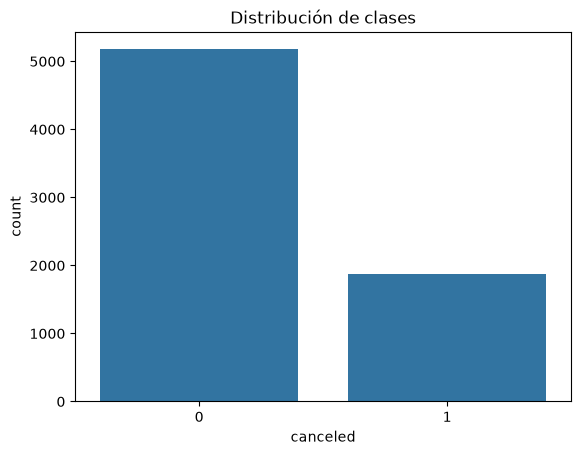

In [20]:
# Balanceo de clases
sns.countplot(contract_copy, x='canceled')
plt.title('Distribución de clases')

plt.show()

In [21]:
print(contract_copy['canceled'].value_counts(normalize=True))

canceled
0    0.73463
1    0.26537
Name: proportion, dtype: float64


El dataframe no contenia la columna objetivo, se puede observar que hay una columna que indica la fecha final (fecha cuando el cliente dejo los servicios) pero en la misma columna se indica que no se ha dejado el servicio con "No" por lo que no esta en un formato adecuado, es por eso que se necesito crear una nueva columna adecuada con 0 para indicar si que el cliente no ha dejado los servicios y 1 para aquellos clientes que si lo ha hecho.

El desbalance en las clases es evidente, como se esperaba hay menos clientes que han dejado los servicios, 73% no han cancelado y 26 si lo han hecho.

#### ¿Existe relación entre la antigüedad del cliente y la cancelación?

In [22]:
# Fecha
reference_date = '2020-02-01 00:00:00'

In [23]:
contract_copy.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,canceled
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5,0
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [24]:
contract_copy['BeginDate'].unique()

<ArrowStringArray>
['2020-01-01', '2017-04-01', '2019-10-01', '2016-05-01', '2019-09-01',
 '2019-03-01', '2018-04-01', '2019-04-01', '2017-07-01', '2014-12-01',
 '2019-01-01', '2018-10-01', '2015-04-01', '2015-09-01', '2018-01-01',
 '2014-05-01', '2015-10-01', '2014-03-01', '2018-05-01', '2019-11-01',
 '2019-02-01', '2016-01-01', '2017-08-01', '2015-12-01', '2014-02-01',
 '2018-06-01', '2019-12-01', '2017-11-01', '2019-06-01', '2016-04-01',
 '2017-02-01', '2018-12-01', '2014-04-01', '2018-09-01', '2014-11-01',
 '2016-07-01', '2015-02-01', '2018-07-01', '2014-08-01', '2016-03-01',
 '2018-08-01', '2014-10-01', '2015-06-01', '2016-08-01', '2019-05-01',
 '2017-03-01', '2016-02-01', '2017-09-01', '2014-09-01', '2017-12-01',
 '2016-12-01', '2017-06-01', '2015-05-01', '2016-10-01', '2016-09-01',
 '2019-08-01', '2019-07-01', '2017-05-01', '2017-10-01', '2014-07-01',
 '2018-03-01', '2015-01-01', '2018-11-01', '2015-03-01', '2018-02-01',
 '2016-06-01', '2015-08-01', '2015-11-01', '2014-06-01', '

In [25]:
# Convertir las columna a datetime
contract_copy['BeginDate'] = pd.to_datetime(contract_copy['BeginDate'], errors='coerce')

# le agregamos la fecha de contrado valido
contract_copy['EndDateReal'] = contract_copy['EndDate'].replace("No", reference_date)
contract_copy['EndDateReal'] = pd.to_datetime(contract_copy['EndDateReal'], errors='coerce')


# Columna antiguedad
antique_days = (contract_copy['EndDateReal'] - contract_copy['BeginDate']).dt.days
contract_copy['antique'] = antique_days.fillna(0).astype(int)

display(contract_copy.head())

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,canceled,EndDateReal,antique
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,2020-02-01,31
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5,0,2020-02-01,1036
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,1,2019-12-01,61
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,2020-02-01,1371
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65,1,2019-11-01,61


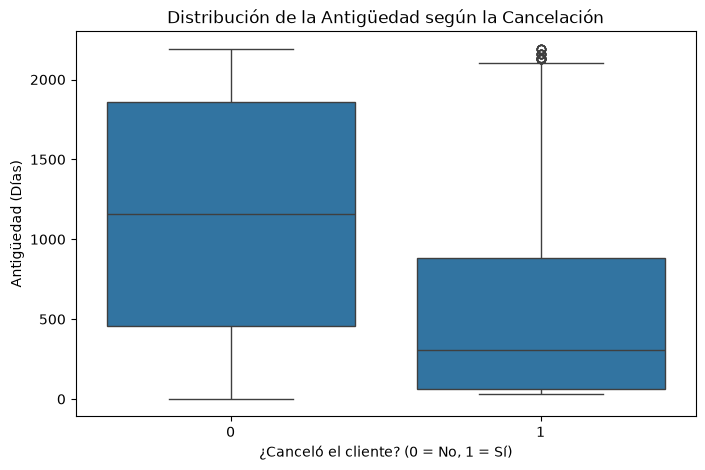

In [26]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=contract_copy, x="canceled", y="antique")

plt.title("Distribución de la Antigüedad según la Cancelación")
plt.xlabel("¿Canceló el cliente? (0 = No, 1 = Sí)")
plt.ylabel("Antigüedad (Días)")
plt.show()

Como la columna antiguedad no se encuentra se tuvo que crear, por lo que antes se comprobo el formato de fecha al igual que con el comando unique revisamos si no existe un valor que puedo generar error como en el caso de la columna EndDate y "No", luego de las comprobaciones convertimos las columnas a tipo de dato datime y finalmente calculamos la antiguedad del cliente tomando en cuenta la hasta la fecha valida que indica la tarea (fecha hasta la cual se tiene que tomar en cuenta).

En cuanto a la distribución de la antiguedad según las clases objetivo: rápidamente se puede interpretar que para los usuarios que no cancelaron es diferente a los que si cancelaron, los clientes que si canceron normalmente lo hicieron con poco tiempo en comparación con los que se mantienen. Otro punto importante que se puede observar es que algunos clientes que cancelaron lo hicieron incluso en los primeros días de unirse.

#### ¿La cantidad de servicios contratados está relacionado con la cancelación?

In [27]:
print('DataFrame contract')
display(contract_copy.sample(3))
print('DataFrame internet')
display(internet_copy.sample(3))

DataFrame contract


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,canceled,EndDateReal,antique
948,7028-DVOIQ,2017-02-01,2020-01-01 00:00:00,Month-to-month,Yes,Electronic check,99.05,3395.8,1,2020-01-01,1064
2854,4644-PIZRT,2018-09-01,No,One year,Yes,Bank transfer (automatic),70.35,1201.65,0,2020-02-01,518
4016,7754-IXRMC,2020-01-01,No,Month-to-month,No,Mailed check,45.35,45.35,0,2020-02-01,31


DataFrame internet


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
2423,1898-JSNDC,DSL,No,Yes,No,No,Yes,No
3992,4759-TRPLW,Fiber optic,No,No,No,No,No,No
3580,1069-XAIEM,Fiber optic,No,No,No,No,No,Yes


In [28]:
# verificar los valores de la columna IntenetService
internet_copy['InternetService'].unique()

<ArrowStringArray>
['DSL', 'Fiber optic']
Length: 2, dtype: str

In [29]:
# ajustar las columnas de servicio
internet_copy['InternetServiceActive'] = internet_copy['InternetService'].replace(['DSL', 'Fiber optic'], 1).fillna(0).astype(int)

internet_copy.sample(5)

internet_columns_transform = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

for col in internet_columns_transform:
    internet_copy[col] = np.where(internet_copy[col] == 'Yes', 1, 0)

internet_copy.sample(5)

,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetServiceActive
3511,4702-IOQDC,Fiber optic,0,0,0,0,0,0,1
462,0308-IVGOK,DSL,0,1,1,1,0,0,1
764,8467-WYNSR,DSL,1,0,0,1,0,0,1
2405,5762-TJXGK,DSL,1,1,1,0,1,1,1
1068,1371-DWPAZ,DSL,1,1,1,1,1,0,1


In [30]:
# Contar los servicios por cliente
internet_copy['services'] = internet_copy[['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'InternetServiceActive']].sum(axis=1)

internet_copy.sample(5)

,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetServiceActive,services
48,4667-QONEA,DSL,1,1,1,1,0,1,1,6
5431,6797-LNAQX,Fiber optic,0,1,0,0,1,1,1,4
4486,5135-GRQJV,Fiber optic,1,1,1,1,1,1,1,7
895,4081-DYXAV,DSL,0,0,0,0,1,1,1,3
2303,5294-IMHHT,Fiber optic,0,1,0,1,0,1,1,4


In [31]:
# Convinar las tablas
contract_internet = pd.merge(contract_copy, internet_copy, how='inner', on='customerID')

contract_internet.sample(5)

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,canceled,EndDateReal,antique,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetServiceActive,services
3153,4256-ZWTZI,2019-09-01,No,Month-to-month,Yes,Mailed check,51.00,286.8,0,2020-02-01,153,DSL,0,0,0,1,0,0,1,2
2223,7299-GNVPL,2018-03-01,No,Month-to-month,No,Mailed check,84.40,1936.85,0,2020-02-01,702,Fiber optic,1,1,0,1,0,0,1,4
1444,8286-AFUYI,2020-01-01,No,Month-to-month,No,Electronic check,47.95,47.95,0,2020-02-01,31,DSL,1,0,0,0,0,0,1,2
4662,4853-OITSN,2019-09-01,No,Month-to-month,Yes,Electronic check,89.15,413.25,0,2020-02-01,153,Fiber optic,1,0,0,0,0,1,1,3
1968,8622-ZLFKO,2019-08-01,No,Month-to-month,Yes,Electronic check,90.75,512.25,0,2020-02-01,184,Fiber optic,0,1,0,0,0,1,1,3


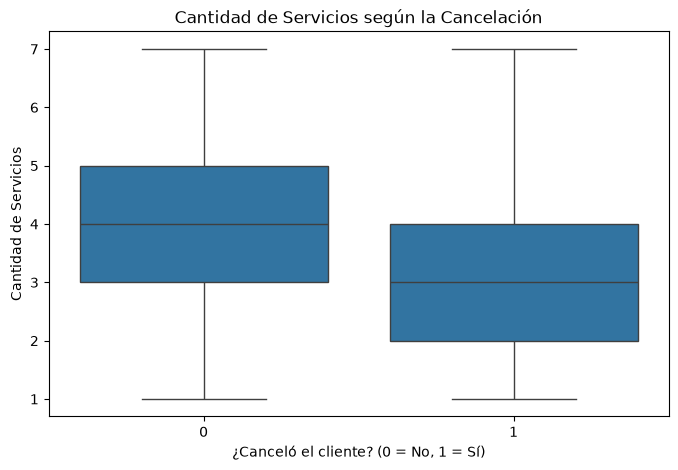

In [32]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=contract_internet,
    x="canceled",
    y="services"
)

plt.title("Cantidad de Servicios según la Cancelación")
plt.xlabel("¿Canceló el cliente? (0 = No, 1 = Sí)")
plt.ylabel("Cantidad de Servicios")
plt.show()

Para completar esta tarea se corrijio los tipos de datos de las columnas que indican con que serivcio cuenta el cliente, se realizo la suma de los servicios y finalmente se unio la tabla contract e internet.

En la gráfica se puede observar que los usuarios que no hicieron churn tienen mayor cantidad de servicios que los clientes que si hicieron churn. Esto nos revela que posiblemente los clientes que tienen más servicios disfrutan ser clientes de interconnect.

#### ¿Existen diferencias en la cancelación según el tipo de plan?

In [33]:
# Verificación de los tipos de contrato
contract_copy['Type'].unique()

<ArrowStringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

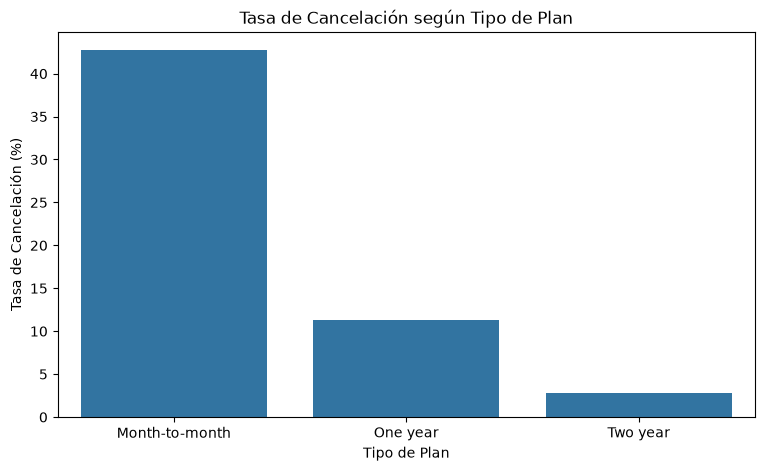

In [34]:
cancel_rate = (
    contract_copy
    .groupby("Type")["canceled"]
    .mean()
    .reset_index()
)

cancel_rate["canceled"] *= 100

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cancel_rate,
    x="Type",
    y="canceled"
)

plt.title("Tasa de Cancelación según Tipo de Plan")
plt.xlabel("Tipo de Plan")
plt.ylabel("Tasa de Cancelación (%)")

plt.show()

Se verifico los tipos de contratos únicos, para luego obtener el proporción por tipo.

Se observa diferencia en la tasa de cancelación entre los tipos de plan o contratos. El plan mensual presenta la mayor proporción de cancelación, mientras que el contrato por 2 años presenta la menor. Esto sugiere que el tipo de plan podría estar relacionado con la cancelación y, por lo tanto, la variable podría ser relevante para el modelo de clasificación.

## Conclusión final

Con el análisis de los datos y el análisis exploratorio realizado comprendo cuáles son las deficiencias de mis datos y las correcciones que tengo que realizar.

Comprendo igualmente que el tipo de tarea de este proyecto es de clasificación binaria.

Respecto al proyecto, puedo observar que los clientes que hacer churn son aquellos clientes que no se compremeten y no adquieren la mayoría de los servicios que interconnect ofrece, usuarios los cuales tienen un tipo de contrato mensual y que tiene la mitad de los servicios que se ofrece, son clientes que tienen más probabilidad de dejar los servicios de interconnect. 

## Preguntas aclaratorias

Veo que en los criterios de evaluación únicamente se centran en métricas y no en rendimiento. ¿Es aceptable un modelo muy complejo que entregue los scores deseados?

## Plan de trabajo

1. Comprensión del problema

La empresa Interconnect desea pronosticar la tasa de cancelación de clientes para poder tomar medidas al detecar si un cliente va a cancelar su suscripción, se le ofreceran códigos promocionales o planes especiales. 

El problema será abordado como una tarea de clasificación binaria, donde la variable objetivo indicará si un cliente canceló o no su suscripción.

2. Lectura de los datos

3. Comprensión de los datos

Se realizará una exploración inicial del conjunto de datos para conocer su estructura y características principales. Se analizarán:

* Número de registros
* Tipos de datos
* Valores ausentes
* Registros duplicados

4. Análisis exploratorio

Se realizará un análisis exploratorio para identificar patrones y posibles relaciones entre las variables disponibles y la cancelación de los clientes.

Se investigarán preguntas como:

* ¿Qué proporción de clientes cancela su suscripción?
* ¿Existe relación entre la antigüedad del cliente y la cancelación?
* ¿La cantidad de servicios contratados está relacionado con la cancelación?
* ¿Existen diferencias en la cancelación según el tipo de plan?

Para ello se utilizarán estadísticas descriptivas y visualizaciones apropiadas.

5. Preparación de los datos

Se prepararán los datos para el entrenamiento de los modelos mediante:

1. Tratamiento de valores ausentes.
2. Eliminación de duplicados cuando corresponda.
3. Corrección de valores inconsistentes.
4. Análisis y tratamiento de valores atípicos cuando sea necesario.
5. Transformación de variables categóricas.
6. Separación de variables predictoras y variable objetivo.
7. División de los datos en conjuntos de entrenamiento y prueba.
8. Aplicación de las transformaciones necesarias evitando fuga de información.

Cuando se de el caso.

6. Desarrollo de modelos

Se entrenarán diferentes algoritmos de clasificación para comparar su capacidad predictiva.

Se considerarán inicialmente:

* Regresión Logística.
* Árbol de Decisión.
* Random Forest.
* LightGBM.
* Red Neuronal

Cuando corresponda, se realizará ajuste de hiperparámetros para mejorar el desempeño de los modelos.

7. Evaluación

Los modelos serán evaluados utilizando métricas apropiadas para el problema de clasificación, incluyendo:

* AUC-ROC
* Exactitud

8. Selección del modelo final

Se compararán los resultados obtenidos por los diferentes modelos y se seleccionará el que presente el mejor desempeño general de acuerdo con las métricas establecidas y las necesidades del problema.

También se considerará la capacidad de generalización e interpretabilidad del modelo.

9. Conclusiones

Finalmente, se analizarán los resultados obtenidos para determinar si el modelo desarrollado permite alcanzar el objetivo planteado.

Se identificarán las principales variables relacionadas con la cancelación y se plantearán posibles aplicaciones de los resultados para apoyar las estrategias de retención de clientes.